In [2]:
import itertools
import numpy as np
from shapely.geometry import Polygon
from shapely.affinity import translate
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon


import math
import random
import json
import os
import re
import numpy as np

from shapely.ops import unary_union

import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon




from svgpathtools import svg2paths2
from collections import defaultdict


from shapely.geometry import Polygon as ShapelyPolygon, MultiPolygon, box
from shapely.affinity import translate, rotate
from shapely.ops import unary_union



In [3]:
def extract_color(attr):
    """
    Extract fill or stroke color from SVG attributes.
    Supports hex and rgb() styles from CorelDRAW.
    """

    # Direct attributes
    if attr.get("fill") and attr["fill"] != "none":
        return attr["fill"]

    if attr.get("stroke") and attr["stroke"] != "none":
        return attr["stroke"]

    style = attr.get("style", "")

    # Hex colors
    m = re.search(r"fill:\s*(#[0-9A-Fa-f]{6})", style)
    if m:
        return m.group(1)

    m = re.search(r"stroke:\s*(#[0-9A-Fa-f]{6})", style)
    if m:
        return m.group(1)

    # rgb() colors (Corel)
    m = re.search(r"(fill|stroke):\s*rgb\([^)]+\)", style)
    if m:
        return m.group(0)  # use full rgb(...) string as key

    return None
    
def parse_filename(filename):
    """
    JB_FRONT_16-18-20.svg  → sizes = ['16','18','20']
    JB_FRONT_M-L-XL.svg    → sizes = ['M','L','XL']
    """

    name = os.path.splitext(filename)[0]

    parts = name.split("_")
    if len(parts) < 3:
        raise ValueError(f"Invalid filename format: {filename}")

    brand = parts[0]
    part = parts[1].upper()
    size_list = parts[2]

    sizes = size_list.split("-")

    return part, sizes

def svg_path_to_polygon(path, svg_attr, samples=40):
    # --- Parse viewBox ---
    vb_x, vb_y, vb_w, vb_h = map(float, svg_attr["viewBox"].split())

    # --- Parse physical size in mm ---
    width_mm = float(svg_attr["width"].replace("mm", ""))
    height_mm = float(svg_attr["height"].replace("mm", ""))

    scale_x = width_mm / vb_w
    scale_y = height_mm / vb_h

    raw = []
    for seg in path:
        for t in np.linspace(0, 1, samples):
            pt = seg.point(t)
            raw.append((pt.real, pt.imag))

    # Convert to inches
    pts = []
    for x, y in raw:
        x_mm = (x - vb_x) * scale_x
        y_mm = (y - vb_y) * scale_y
        pts.append((x_mm / 25.4, y_mm / 25.4))

    # Flip Y and normalize
    max_y = max(y for _, y in pts)
    pts = [(x, max_y - y) for x, y in pts]

    min_x = min(x for x, _ in pts)
    min_y = min(y for _, y in pts)
    pts = [(x - min_x, y - min_y) for x, y in pts]

    return pts

def load_svg_file(svg_path):

    paths, attrs, svg_attr = svg2paths2(svg_path)

    color_groups = defaultdict(list)
    no_color_paths = []

    # --- classify paths ---
    for path, attr in zip(paths, attrs):
        color = extract_color(attr)

        if color:
            color_groups[color].append(path)
        else:
            no_color_paths.append(path)

    polygons = []

    # =====================================================
    # CASE A — colored pieces exist (preferred)
    # =====================================================
    if color_groups:

        for color, group in color_groups.items():

            sub_polys = []

            for p in group:
                pts = svg_path_to_polygon(p, svg_attr)

                if len(pts) < 3:
                    continue

                poly = ShapelyPolygon(pts)

                if poly.area < 0.01:
                    continue

                if not poly.is_valid:
                    poly = poly.buffer(0)

                sub_polys.append(poly)

            if not sub_polys:
                continue

            merged = unary_union(sub_polys)

            if merged.geom_type == "MultiPolygon":
                for g in merged.geoms:
                    if g.area > 0.05:
                        polygons.append(g)
            else:
                if merged.area > 0.05:
                    polygons.append(merged)

    # =====================================================
    # CASE B — no colors → treat each path as separate piece
    # =====================================================
    else:
        for p in paths:

            pts = svg_path_to_polygon(p, svg_attr)

            if len(pts) < 3:
                continue

            poly = ShapelyPolygon(pts)

            if poly.area < 0.05:
                continue

            if not poly.is_valid:
                poly = poly.buffer(0)
            
            polygons.append(poly)

    if not polygons:
        raise ValueError(f"No valid polygons found in {svg_path}")
    
    return polygons
    
def process_design_folder(folder_path):
    all_shapes = []

    for file in os.listdir(folder_path):
        if not file.lower().endswith(".svg"):
            continue

        part, sizes = parse_filename(file)
        svg_path = os.path.join(folder_path, file)

        polygons = load_svg_file(svg_path)
        
        sized_polys = assign_sizes(polygons, sizes)
        
        for size, poly in sized_polys:

            # assign_sizes may return nested tuple
            if isinstance(poly, tuple):
                poly = poly[1]
        
            # if multiple polygons
            if isinstance(poly, list):
                for p in poly:
                    all_shapes.append({
                        "part": part,
                        "size": size,
                        "polygon": p
                    })
            else:
                all_shapes.append({
                    "part": part,
                    "size": size,
                    "polygon": poly
                })
    
    # Save structured output
    '''
    out_path = os.path.join(folder_path, "parsed_shapes.json")
    with open(out_path, "w") as f:
        json.dump(all_shapes, f, indent=2)
    '''
    return all_shapes            

def assign_sizes(polygons, sizes):
    assert len(polygons) == len(sizes), (
        f"Size count mismatch: {len(polygons)} polygons vs {len(sizes)} sizes"
    )

    # sort by area (small → big)
    areas = [(poly.area, poly) for poly in polygons]
    areas.sort(key=lambda x: x[0])

    validate_monotonic_areas(polygons)

    result = []

    for size, (_, poly) in zip(sizes, areas):
        # 🔴 STORE ACTUAL SHAPELY POLYGON
        result.append((size, poly))

    return result


def validate_monotonic_areas(polygons):
    areas = sorted(poly.area for poly in polygons)
    for i in range(len(areas) - 1):
        ratio = areas[i + 1] / areas[i]
        if ratio < 1.02:
            raise ValueError(
                "Two sizes have nearly identical area. "
                "Check colors or duplicate patterns."
            )



    
# ---------- NORMALIZE INPUT ----------

def extract_polys(shape_items):
    """
    Convert loader output → internal structure
    Ensures shapely polygon always used
    """
    polys = []

    for s in shape_items:
        p = s["polygon"]

        # already shapely
        if isinstance(p, Polygon):
            poly = p

        # coords list
        else:
            poly = Polygon(p)

        poly = clean(poly)

        polys.append({
            "poly": poly,
            "part": s.get("part",""),
            "size": s.get("size","")
        })

    # sort largest first (important)
    polys.sort(key=lambda x: x["poly"].area, reverse=True)

    print("polygons loaded:", len(polys))
    return polys




def to_poly(coords):
    return clean(Polygon(coords))
    
def layout_to_kpi_items(polys):
    """
    Convert shapely polygon list into
    format expected by evaluate_kpis()
    """
    items = []

    for p in polys:
        coords = list(p.exterior.coords)
        items.append({
            "polygon": coords
        })

    return items
    
def evaluate_kpis(placed_shapes, strip_width):

    max_y = 0.0
    used_area = 0.0

    for item in placed_shapes:

        poly = item["polygon"]

        # ---- HEIGHT (marker length) ----
        top_y = poly.bounds[3]
        if top_y > max_y:
            max_y = top_y

        # ---- USED FABRIC AREA ----
        used_area += poly.area

    total_area = strip_width * max_y

    empty_ratio = 0.0
    if total_area > 0:
        empty_ratio = 1.0 - (used_area / total_area)

    return {
        "layer_length_in": round(max_y, 3),
        "used_area_in2": round(used_area, 3),
        "total_area_in2": round(total_area, 3),
        "empty_ratio": round(empty_ratio, 4)
    }


def convert_for_kpi(placed_shapes):
    kpi_items = []

    for s in placed_shapes:
        coords = list(s.poly.exterior.coords)
        kpi_items.append({
            "part": s.part,
            "size": s.size,
            "polygon": coords
        })

    return kpi_items

    

def compute_score(placed, strip_width):
    polys = []

    for item in placed:
        poly = item["polygon"]
        if hasattr(poly, "area"):
            shp = poly
        else:
            shp = ShapelyPolygon(poly)
        polys.append(shp)

    piece_area = sum(p.area for p in polys)
    max_y = max(p.bounds[3] for p in polys)

    marker_area = strip_width * max_y
    wastage = (marker_area - piece_area) / marker_area

    return wastage, max_y   # ← NOW RETURNS TWO VALUES


def build_shapes(shape_items):
    shapes = []
    for item in shape_items:
        poly = item["polygon"]
        if not hasattr(poly, "bounds"):
            poly = Polygon(poly)

        shapes.append(
            Shape(item["part"], item["size"], poly)
        )
    return shapes



class Shape:
    def __init__(self, part, size, poly):
        self.part = part
        self.size = size
        self.poly = poly

    def area(self):
        return self.poly.area

    def copy(self):
        return Shape(self.part, self.size,
                     Polygon(self.poly.exterior.coords))

def place_shape(shape, x, y):
    minx, miny, maxx, maxy = shape.poly.bounds
    moved = translate(shape.poly,
                      xoff=x - minx,
                      yoff=y - miny)
    return Shape(shape.part, shape.size, moved)

def intersects_any(test_shape, placed):
    for p in placed:
        if test_shape.poly.intersects(p.poly):
            return True
    return False




In [4]:
# ---------- BASIC HELPERS ----------

def clean(poly):
    """Fix tiny topology issues"""
    return poly.buffer(0)


def width(poly):
    b = poly.bounds
    return b[2] - b[0]


def height(poly):
    b = poly.bounds
    return b[3] - b[1]

In [5]:
def render_layout(layout, strip_width, title="ROW"):

    if not layout:
        print("nothing to render")
        return

    fig, ax = plt.subplots(figsize=(12,6))
    ax.set_title(title)

    max_y = 0

    for item in layout:
        poly = item["polygon"]
        part = item.get("part","")
        size = item.get("size","")

        x,y = poly.exterior.xy
        ax.fill(x,y,alpha=0.5)
        ax.text(poly.centroid.x, poly.centroid.y,
                f"{part}-{size}",
                ha="center", va="center", fontsize=8)

        max_y = max(max_y, poly.bounds[3])

    ax.set_xlim(0, strip_width)
    ax.set_ylim(max_y+5, 0)
    ax.set_aspect("equal")
    plt.show()


In [9]:
# ---------- SKYLINE DROP ----------

def drop_piece(poly, placed_polys, step=0.5):

    # start high
    test = translate(poly, yoff=200)

    while True:
        moved = translate(test, yoff=-step)

        # ---- FLOOR HIT ----
        if moved.bounds[1] <= 0:
            # snap EXACTLY to floor
            floor_snap = translate(moved, yoff=-moved.bounds[1])
            return floor_snap

        # ---- COLLISION CHECK ----
        collision = False
        for p in placed_polys:
            if moved.intersects(p):
                collision = True
                break

        if collision:
            return test

        test = moved




def place_row_and_score(row_items, placed_polys, strip_width):

    best_layout = None
    best_score = 1e18

    # try permutations (limit to keep fast)
    for perm in list(itertools.permutations(row_items))[:24]:

        # --- compute total row width ---
        widths = []
        for item in perm:
            p = item["polygon"]
            widths.append(p.bounds[2] - p.bounds[0])

        total_w = sum(widths)

        if total_w > strip_width:
            continue

        # -------------------------------------------------
        # v18_2 CHANGE: LEFT-ALIGNED ONLY (NO SLIDING)
        # -------------------------------------------------
        x_cursor = 0

        shifted = []
        for item in perm:
            p = item["polygon"]
            minx = p.bounds[0]

            moved = translate(p, x_cursor - minx, 0)
            shifted.append(moved)

            x_cursor += (p.bounds[2] - p.bounds[0])

        # --- drop each piece onto skyline ---
        dropped = []
        base = placed_polys.copy()

        for poly in shifted:
            d = drop_piece(poly, base)
            dropped.append(d)
            base.append(d)

        # --- SCORE (original v18 scoring) ---
        tops = [p.bounds[3] for p in dropped]
        bottoms = [p.bounds[1] for p in dropped]

        # bottom emptiness (floating above skyline)
        bottom_emptiness = sum(bottoms)

        # skyline smoothness
        top_variation = max(tops) - min(tops)

        score = bottom_emptiness + top_variation

        if score < best_score:
            best_score = score

            best_layout = []
            for item, poly in zip(perm, dropped):
                best_layout.append({
                    "part": item["part"],
                    "size": item["size"],
                    "polygon": poly
                })

    return best_layout, best_score



# -----------------------------------------------------------
# BUILD BEST ROW USING STACK LOGIC
# STOP WHEN HEIGHT GETS WORSE
# -----------------------------------------------------------
def build_best_row(remaining_items, placed_polys, strip_width):

    print(">> ENTER build_best_row")

    best_layout = None
    best_score = None   # ← important

    i = 0
    while i < len(remaining_items):

        # ---- BUILD STACK FIRST ----
        stack = []
        width_used = 0

        j = i
        while j < len(remaining_items):

            item = remaining_items[j]
            poly = item["polygon"]

            pw = poly.bounds[2] - poly.bounds[0]

            if width_used + pw > strip_width:
                break

            stack.append(item)
            width_used += pw
            j += 1

        if not stack:
            i += 1
            continue

        print("\n   STACK BUILT")
        print("   pieces:", len(stack))
        print("   total width:", round(width_used,2))

        for p in stack:
            w = p["polygon"].bounds[2] - p["polygon"].bounds[0]
            print("      ", p["part"], p["size"], "| width:", round(w,2))

        # ---- SCORE ONLY AFTER STACK READY ----
        layout, score = place_row_and_score(stack, placed_polys, strip_width)

        print("   → SCORE:", round(score,3))

        # ---- FIRST SCORE ----
        if best_score is None:
            best_score = score
            best_layout = layout
            i += 1
            continue

        # ---- STRICT IMPROVEMENT RULE ----
        if score < best_score - 0.001:
            # improvement → accept + continue
            best_score = score
            best_layout = layout
            i += 1
            continue

        else:
            i += 1
            continue

    print(">> BEST ROW LOCKED | score:", round(best_score,3))
    return best_layout







def run_engine(shape_items, strip_width):

    print("\n==============================")
    print(" MARKER ENGINE START")
    print("==============================")

    # remaining pieces (full info)
    remaining = shape_items[:]

    # only polygons placed so far
    placed_polys = []
    placed_items = []
    row_id = 1

    while remaining:

        print("\n==============================")
        print(f"BUILDING ROW {row_id}")
        print("remaining pieces:", len(remaining))
        print("==============================")

        remaining.sort(
            key=lambda x: x["polygon"].area,
            reverse=True
        )
        
        # send only polygon list to row builder
        remaining_polys = [r["polygon"] for r in remaining]
        
        
        row_layout = build_best_row(
            remaining,
            placed_polys,
            strip_width
        )

        if row_layout is None:
            print("❌ no row possible — stopping")
            break

        # ---- MATCH layout polys back to shape_items ----
        row_items = []

        for poly in row_layout:

            # if dict accidentally returned → extract polygon
            if isinstance(poly, dict):
                poly = poly["polygon"]
        
            for r in remaining:
                rp = r["polygon"]
        
                if (
                    abs(poly.area - rp.area) < 0.01 and
                    abs((poly.bounds[2]-poly.bounds[0]) - (rp.bounds[2]-rp.bounds[0])) < 0.01 and
                    abs((poly.bounds[3]-poly.bounds[1]) - (rp.bounds[3]-rp.bounds[1])) < 0.01
                ):
                    row_items.append(r)
                    break


        # ---- remove used from remaining ----
        for item in row_items:
            if item in remaining:
                remaining.remove(item)

        # ---- add placed polys ----
        # ALWAYS store only shapely polygons
        clean_polys = []
        
        for p in row_layout:
            if isinstance(p, dict):
                clean_polys.append(p["polygon"])
            else:
                clean_polys.append(p)
        
        placed_polys.extend(clean_polys)
        placed_items.extend(row_layout)
        print(f"ROW {row_id} LOCKED — pieces:", len(row_items))

        # 🔷 RENDER AFTER EACH ROW (THIS IS WHAT YOU WANT)
        render_layout(
            row_layout,
            strip_width,
            title=f"ROW {row_id}"
        )

        row_id += 1

    print("\n==============================")
    print(" FINAL MARKER COMPLETE")
    print("==============================")

    # 🔷 FINAL FULL RENDER
    render_layout(
        placed_items,
        strip_width,
        title="FINAL MARKER"
    )
    
    # 🔷 KPI CALCULATION
    kpis = evaluate_kpis(placed_items, strip_width)
    
    print("\n===== FINAL KPIs =====")
    for k,v in kpis.items():
        print(k, ":", v)
    


polygons loaded: 12


KeyError: 'polygon'

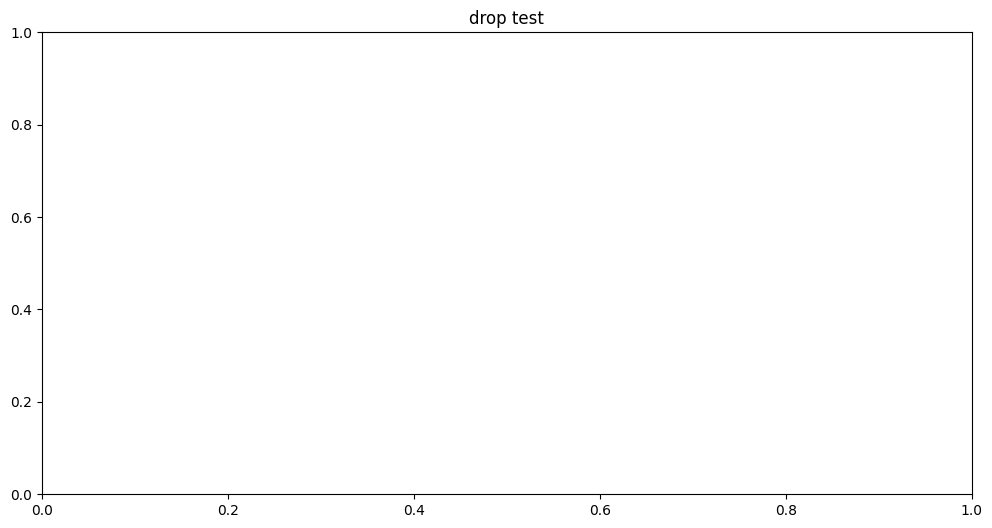

In [7]:
# ---- TEST DROP ----

def test_drop(shape_items, strip_width):
    items = extract_polys(shape_items)

    placed = []

    for i, item in enumerate(items[:3]):  # test first 3 only
        p = item["poly"]

        # place side by side
        if placed:
            right = max(x.bounds[2] for x in placed)
        else:
            right = 0

        moved = translate(p, right - p.bounds[0], 0)
        dropped = drop_piece(moved, [x for x in placed])

        placed.append(dropped)

    # render
    out = []
    for i,p in enumerate(placed):
        out.append({"poly":p,"part":"T","size":str(i)})

    render_layout(out, strip_width, "drop test")

def test_place_row(polys, strip_width=36):

    print("Testing place_row_and_score()")
    print("pieces:", len(polys))

    # take first 3 pieces only
    test_polys = polys[:3]

    placed = []  # nothing below yet

    layout, score = place_row_and_score(test_polys, placed, strip_width)

    print("best score:", score)

    if layout is None:
        print("❌ no layout returned")
        return

    render_layout(layout, strip_width, title="place_row test")



def test_build_row(shape_items, strip_width):

    print("\n==============================")
    print("TESTING ROW BUILDER")
    print("==============================")

    # convert to correct format
    remaining = []
    for s in shape_items:
        remaining.append({
            "poly": s["polygon"],   # shapely polygon
            "part": s["part"],
            "size": s["size"]
        })

    placed = []  # nothing placed yet

    row, used_idx = build_best_row(
        remaining,
        placed,
        strip_width,
        max_stack=5
    )

    if row is None:
        print("\n❌ No row returned")
        return

    print("\n✅ ROW BUILT")
    print("pieces in row:", len(row))

    for r in row:
        print(f'{r["part"]}-{r["size"]}',
              "top:", round(r["poly"].bounds[3],2))



        




design_folder = "JK-123"
STRIP_WIDTH = 36

shape_items = process_design_folder(design_folder)

test_drop(shape_items, STRIP_WIDTH)
polys = [s["polygon"] for s in shape_items]


#test_place_row(polys)


#test_build_row(shape_items, STRIP_WIDTH)
#row, used = build_best_row(polys, [], STRIP_WIDTH)



 MARKER ENGINE START

BUILDING ROW 1
remaining pieces: 12
>> ENTER build_best_row

   STACK BUILT
   pieces: 3
   total width: 35.4
       BACK XL | width: 12.1
       FRONT XL | width: 12.1
       BACK L | width: 11.2
   → SCORE: 1.0

   STACK BUILT
   pieces: 3
   total width: 34.5
       FRONT XL | width: 12.1
       BACK L | width: 11.2
       FRONT L | width: 11.2
   → SCORE: 1.0

   STACK BUILT
   pieces: 3
   total width: 32.9
       BACK L | width: 11.2
       FRONT L | width: 11.2
       BACK M | width: 10.5
   → SCORE: 1.0

   STACK BUILT
   pieces: 3
   total width: 32.2
       FRONT L | width: 11.2
       BACK M | width: 10.5
       FRONT M | width: 10.5
   → SCORE: 1.0

   STACK BUILT
   pieces: 3
   total width: 30.52
       BACK M | width: 10.5
       FRONT M | width: 10.5
       SLEEVE-LEFT XL | width: 9.52
   → SCORE: 6.652

   STACK BUILT
   pieces: 3
   total width: 29.55
       FRONT M | width: 10.5
       SLEEVE-LEFT XL | width: 9.52
       SLEEVE-RIGHT XL | width

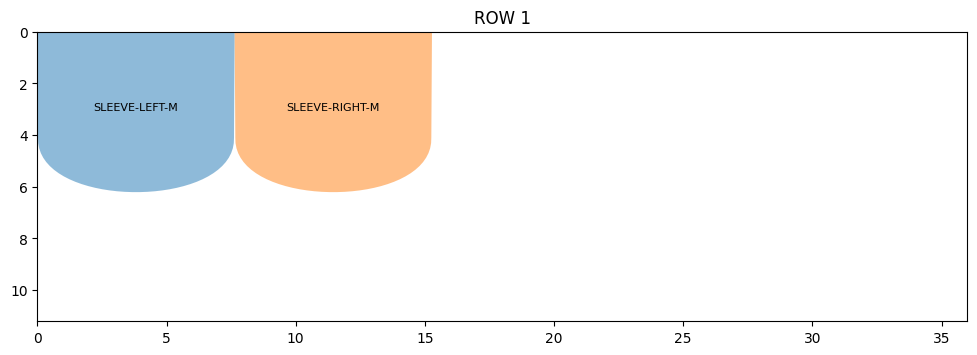


BUILDING ROW 2
remaining pieces: 11
>> ENTER build_best_row

   STACK BUILT
   pieces: 3
   total width: 35.4
       BACK XL | width: 12.1
       FRONT XL | width: 12.1
       BACK L | width: 11.2
   → SCORE: 19.5

   STACK BUILT
   pieces: 3
   total width: 34.5
       FRONT XL | width: 12.1
       BACK L | width: 11.2
       FRONT L | width: 11.2
   → SCORE: 18.5

   STACK BUILT
   pieces: 3
   total width: 32.9
       BACK L | width: 11.2
       FRONT L | width: 11.2
       BACK M | width: 10.5
   → SCORE: 19.5

   STACK BUILT
   pieces: 3
   total width: 32.2
       FRONT L | width: 11.2
       BACK M | width: 10.5
       FRONT M | width: 10.5
   → SCORE: 18.5

   STACK BUILT
   pieces: 3
   total width: 30.52
       BACK M | width: 10.5
       FRONT M | width: 10.5
       SLEEVE-LEFT XL | width: 9.52
   → SCORE: 19.652

   STACK BUILT
   pieces: 3
   total width: 29.55
       FRONT M | width: 10.5
       SLEEVE-LEFT XL | width: 9.52
       SLEEVE-RIGHT XL | width: 9.52
   → SCORE

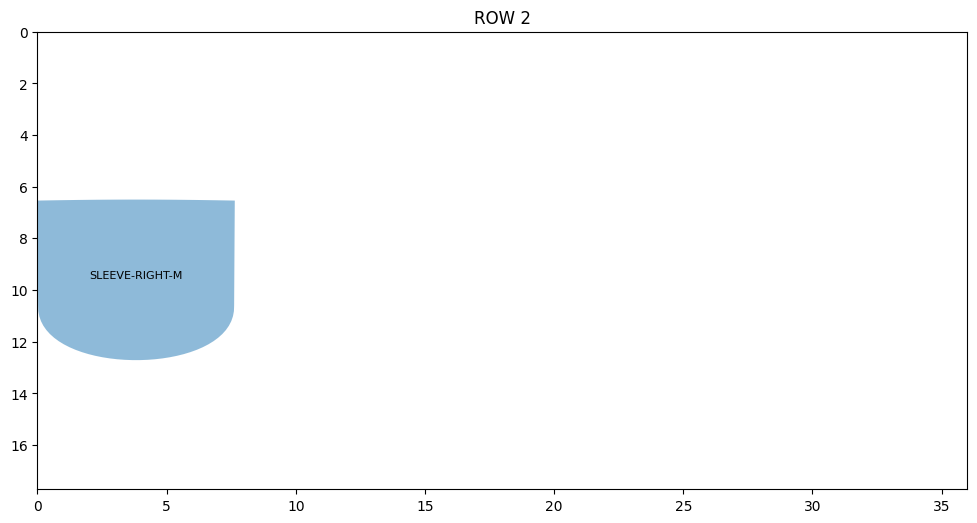


BUILDING ROW 3
remaining pieces: 10
>> ENTER build_best_row

   STACK BUILT
   pieces: 3
   total width: 35.4
       BACK XL | width: 12.1
       FRONT XL | width: 12.1
       BACK L | width: 11.2
   → SCORE: 31.5

   STACK BUILT
   pieces: 3
   total width: 34.5
       FRONT XL | width: 12.1
       BACK L | width: 11.2
       FRONT L | width: 11.2
   → SCORE: 31.5

   STACK BUILT
   pieces: 3
   total width: 32.9
       BACK L | width: 11.2
       FRONT L | width: 11.2
       BACK M | width: 10.5
   → SCORE: 31.5

   STACK BUILT
   pieces: 3
   total width: 32.2
       FRONT L | width: 11.2
       BACK M | width: 10.5
       FRONT M | width: 10.5
   → SCORE: 31.5

   STACK BUILT
   pieces: 3
   total width: 30.52
       BACK M | width: 10.5
       FRONT M | width: 10.5
       SLEEVE-LEFT XL | width: 9.52
   → SCORE: 26.0

   STACK BUILT
   pieces: 3
   total width: 29.55
       FRONT M | width: 10.5
       SLEEVE-LEFT XL | width: 9.52
       SLEEVE-RIGHT XL | width: 9.52
   → SCORE: 

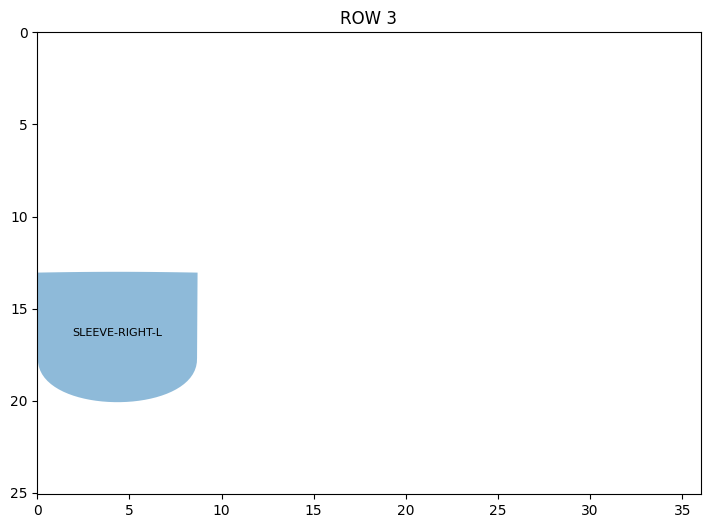


BUILDING ROW 4
remaining pieces: 9
>> ENTER build_best_row

   STACK BUILT
   pieces: 3
   total width: 35.4
       BACK XL | width: 12.1
       FRONT XL | width: 12.1
       BACK L | width: 11.2
   → SCORE: 46.5

   STACK BUILT
   pieces: 3
   total width: 34.5
       FRONT XL | width: 12.1
       BACK L | width: 11.2
       FRONT L | width: 11.2
   → SCORE: 46.5

   STACK BUILT
   pieces: 3
   total width: 32.9
       BACK L | width: 11.2
       FRONT L | width: 11.2
       BACK M | width: 10.5
   → SCORE: 46.5

   STACK BUILT
   pieces: 3
   total width: 32.2
       FRONT L | width: 11.2
       BACK M | width: 10.5
       FRONT M | width: 10.5
   → SCORE: 46.5

   STACK BUILT
   pieces: 3
   total width: 30.52
       BACK M | width: 10.5
       FRONT M | width: 10.5
       SLEEVE-LEFT XL | width: 9.52
   → SCORE: 40.848

   STACK BUILT
   pieces: 3
   total width: 29.55
       FRONT M | width: 10.5
       SLEEVE-LEFT XL | width: 9.52
       SLEEVE-RIGHT XL | width: 9.52
   → SCORE:

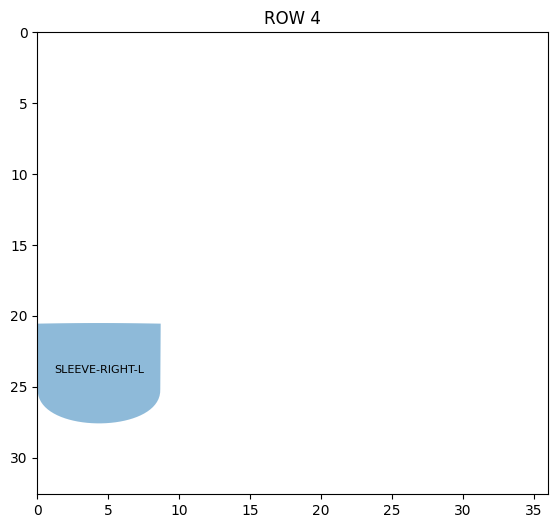


BUILDING ROW 5
remaining pieces: 8
>> ENTER build_best_row

   STACK BUILT
   pieces: 3
   total width: 35.4
       BACK XL | width: 12.1
       FRONT XL | width: 12.1
       BACK L | width: 11.2
   → SCORE: 61.5

   STACK BUILT
   pieces: 3
   total width: 34.5
       FRONT XL | width: 12.1
       BACK L | width: 11.2
       FRONT L | width: 11.2
   → SCORE: 61.5

   STACK BUILT
   pieces: 3
   total width: 32.9
       BACK L | width: 11.2
       FRONT L | width: 11.2
       BACK M | width: 10.5
   → SCORE: 61.5

   STACK BUILT
   pieces: 3
   total width: 32.2
       FRONT L | width: 11.2
       BACK M | width: 10.5
       FRONT M | width: 10.5
   → SCORE: 61.5

   STACK BUILT
   pieces: 3
   total width: 30.52
       BACK M | width: 10.5
       FRONT M | width: 10.5
       SLEEVE-LEFT XL | width: 9.52
   → SCORE: 55.848

   STACK BUILT
   pieces: 3
   total width: 29.55
       FRONT M | width: 10.5
       SLEEVE-LEFT XL | width: 9.52
       SLEEVE-RIGHT XL | width: 9.52
   → SCORE:

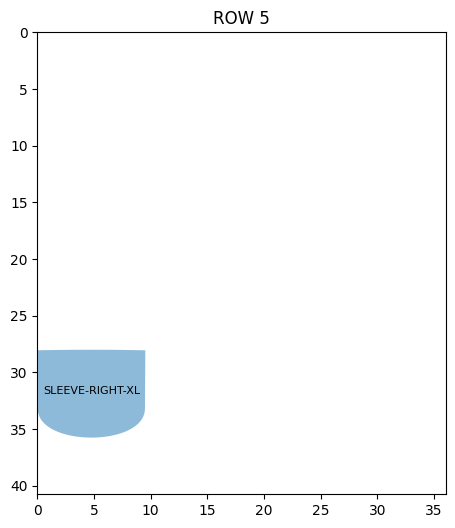


BUILDING ROW 6
remaining pieces: 7
>> ENTER build_best_row

   STACK BUILT
   pieces: 3
   total width: 35.4
       BACK XL | width: 12.1
       FRONT XL | width: 12.1
       BACK L | width: 11.2
   → SCORE: 77.5

   STACK BUILT
   pieces: 3
   total width: 34.5
       FRONT XL | width: 12.1
       BACK L | width: 11.2
       FRONT L | width: 11.2
   → SCORE: 77.5

   STACK BUILT
   pieces: 3
   total width: 32.9
       BACK L | width: 11.2
       FRONT L | width: 11.2
       BACK M | width: 10.5
   → SCORE: 77.5

   STACK BUILT
   pieces: 3
   total width: 32.2
       FRONT L | width: 11.2
       BACK M | width: 10.5
       FRONT M | width: 10.5
   → SCORE: 77.5

   STACK BUILT
   pieces: 3
   total width: 30.52
       BACK M | width: 10.5
       FRONT M | width: 10.5
       SLEEVE-RIGHT XL | width: 9.52
   → SCORE: 71.848

   STACK BUILT
   pieces: 2
   total width: 20.02
       FRONT M | width: 10.5
       SLEEVE-RIGHT XL | width: 9.52
   → SCORE: 65.348

   STACK BUILT
   pieces: 

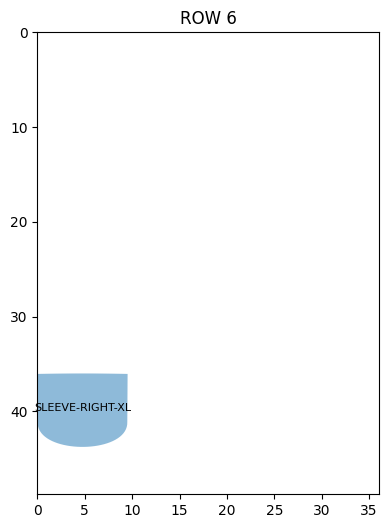


BUILDING ROW 7
remaining pieces: 6
>> ENTER build_best_row

   STACK BUILT
   pieces: 3
   total width: 35.4
       BACK XL | width: 12.1
       FRONT XL | width: 12.1
       BACK L | width: 11.2
   → SCORE: 93.5

   STACK BUILT
   pieces: 3
   total width: 34.5
       FRONT XL | width: 12.1
       BACK L | width: 11.2
       FRONT L | width: 11.2
   → SCORE: 93.5

   STACK BUILT
   pieces: 3
   total width: 32.9
       BACK L | width: 11.2
       FRONT L | width: 11.2
       BACK M | width: 10.5
   → SCORE: 93.5

   STACK BUILT
   pieces: 3
   total width: 32.2
       FRONT L | width: 11.2
       BACK M | width: 10.5
       FRONT M | width: 10.5
   → SCORE: 93.5

   STACK BUILT
   pieces: 2
   total width: 21.0
       BACK M | width: 10.5
       FRONT M | width: 10.5
   → SCORE: 88.0

   STACK BUILT
   pieces: 1
   total width: 10.5
       FRONT M | width: 10.5
   → SCORE: 44.0
>> BEST ROW LOCKED | score: 44.0
ROW 7 LOCKED — pieces: 1


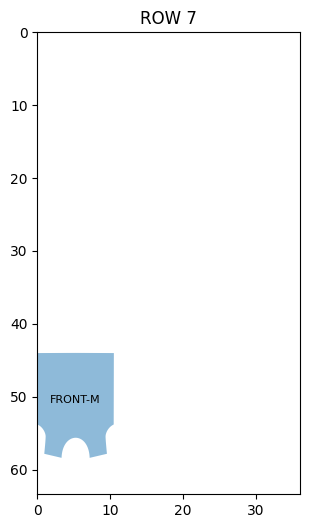


BUILDING ROW 8
remaining pieces: 5
>> ENTER build_best_row

   STACK BUILT
   pieces: 3
   total width: 35.4
       BACK XL | width: 12.1
       FRONT XL | width: 12.1
       BACK L | width: 11.2
   → SCORE: 122.5

   STACK BUILT
   pieces: 3
   total width: 34.5
       FRONT XL | width: 12.1
       BACK L | width: 11.2
       FRONT L | width: 11.2
   → SCORE: 122.5

   STACK BUILT
   pieces: 3
   total width: 32.9
       BACK L | width: 11.2
       FRONT L | width: 11.2
       BACK M | width: 10.5
   → SCORE: 123.5

   STACK BUILT
   pieces: 2
   total width: 21.7
       FRONT L | width: 11.2
       BACK M | width: 10.5
   → SCORE: 116.0

   STACK BUILT
   pieces: 1
   total width: 10.5
       BACK M | width: 10.5
   → SCORE: 58.5
>> BEST ROW LOCKED | score: 58.5
ROW 8 LOCKED — pieces: 1


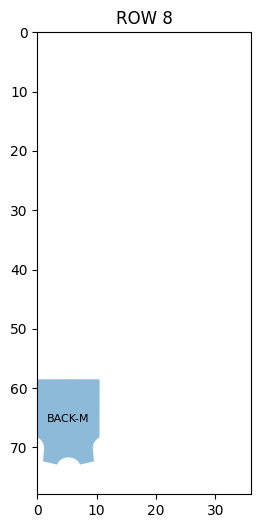


BUILDING ROW 9
remaining pieces: 4
>> ENTER build_best_row

   STACK BUILT
   pieces: 3
   total width: 35.4
       BACK XL | width: 12.1
       FRONT XL | width: 12.1
       BACK L | width: 11.2
   → SCORE: 151.5

   STACK BUILT
   pieces: 3
   total width: 34.5
       FRONT XL | width: 12.1
       BACK L | width: 11.2
       FRONT L | width: 11.2
   → SCORE: 151.5

   STACK BUILT
   pieces: 2
   total width: 22.4
       BACK L | width: 11.2
       FRONT L | width: 11.2
   → SCORE: 146.0

   STACK BUILT
   pieces: 1
   total width: 11.2
       FRONT L | width: 11.2
   → SCORE: 73.0
>> BEST ROW LOCKED | score: 73.0
ROW 9 LOCKED — pieces: 1


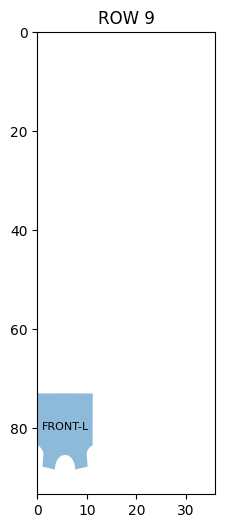


BUILDING ROW 10
remaining pieces: 3
>> ENTER build_best_row

   STACK BUILT
   pieces: 3
   total width: 35.4
       BACK XL | width: 12.1
       FRONT XL | width: 12.1
       BACK L | width: 11.2
   → SCORE: 183.5

   STACK BUILT
   pieces: 2
   total width: 23.3
       FRONT XL | width: 12.1
       BACK L | width: 11.2
   → SCORE: 176.0

   STACK BUILT
   pieces: 1
   total width: 11.2
       BACK L | width: 11.2
   → SCORE: 88.5
>> BEST ROW LOCKED | score: 88.5
ROW 10 LOCKED — pieces: 1


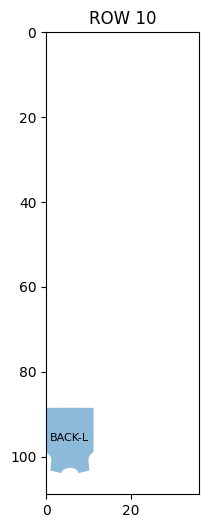


BUILDING ROW 11
remaining pieces: 2
>> ENTER build_best_row

   STACK BUILT
   pieces: 2
   total width: 24.2
       BACK XL | width: 12.1
       FRONT XL | width: 12.1
   → SCORE: 208.0

   STACK BUILT
   pieces: 1
   total width: 12.1
       FRONT XL | width: 12.1
   → SCORE: 104.0
>> BEST ROW LOCKED | score: 104.0
ROW 11 LOCKED — pieces: 1


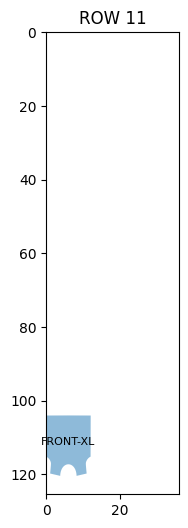


BUILDING ROW 12
remaining pieces: 1
>> ENTER build_best_row

   STACK BUILT
   pieces: 1
   total width: 12.1
       BACK XL | width: 12.1
   → SCORE: 120.5
>> BEST ROW LOCKED | score: 120.5
ROW 12 LOCKED — pieces: 1


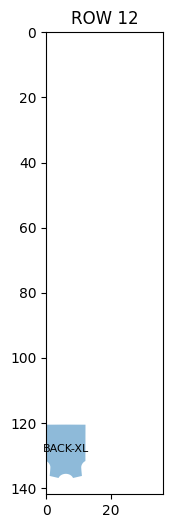


 FINAL MARKER COMPLETE


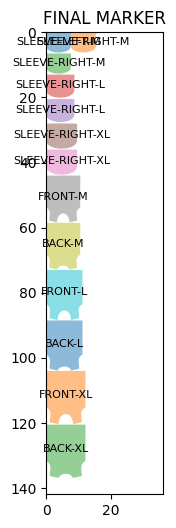


===== FINAL KPIs =====
layer_length_in : 136.9
used_area_in2 : 1315.631
total_area_in2 : 4928.399
empty_ratio : 0.7331


In [10]:
design_folder = "JK-123"
STRIP_WIDTH = 36


shape_items = process_design_folder(design_folder)

run_engine(shape_items, STRIP_WIDTH)


In [ ]:
shape_items